# Porto Seguro Safe Driver Prediction

## Project Overview

The objective of this project is to predict the probability that a driver will initiate an insurance claim in the following year.

This project is based on the Kaggle **Porto Seguro Safe Driver Prediction** competition, which presents a binary classification problem with a highly imbalanced target variable.

The primary focus is to explore and compare different machine learning and deep learning approaches, understand their performance, and investigate how neural network architectures and categorical feature representations affect predictive performance.

### Objectives

- Perform exploratory data analysis and understand the dataset.
- Develop an appropriate preprocessing pipeline.
- Establish baseline performance using classical machine learning algorithms.
- Implement neural networks using PyTorch.
- Explore categorical embeddings as an alternative to one-hot encoding.
- Apply Optuna for hyperparameter optimization.
- Compare models using appropriate evaluation metrics.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report
)
from sklearn.ensemble import RandomForestClassifier
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import torch
import copy
from tqdm.auto import tqdm
import optuna
from optuna.visualization import (
    plot_optimization_history,
    plot_param_importances,
    plot_parallel_coordinate
)

## 1. Dataset and Problem Understanding

The Porto Seguro dataset contains anonymized driver-related features used to predict the probability of an insurance claim.

### Problem Type

- **Task:** Binary Classification
- **Target Variable:** `target`
- **Class 0:** No insurance claim
- **Class 1:** Insurance claim

The dataset is highly imbalanced, with significantly fewer positive examples than negative examples.

This class imbalance makes conventional accuracy an unreliable evaluation metric. Therefore, this project focuses on ranking-based and precision-recall evaluation metrics.

### Dataset Source

[Kaggle - Porto Seguro Safe Driver Prediction](https://www.kaggle.com/competitions/porto-seguro-safe-driver-prediction)

In [2]:
df = pd.read_csv("train.csv")

In [3]:
df.head(20)

,id,target,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,...,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin
0,7,0,2,2,5,1,0,0,1,0,...,9,1,5,8,0,1,1,0,0,1
1,9,0,1,1,7,0,0,0,0,1,...,3,1,1,9,0,1,1,0,1,0
2,13,0,5,4,9,1,0,0,0,1,...,4,2,7,7,0,1,1,0,1,0
3,16,0,0,1,2,0,0,1,0,0,...,2,2,4,9,0,0,0,0,0,0
4,17,0,0,2,0,1,0,1,0,0,...,3,1,1,3,0,0,0,1,1,0
5,19,0,5,1,4,0,0,0,0,0,...,4,2,0,9,0,1,0,1,1,1
6,20,0,2,1,3,1,0,0,1,0,...,3,0,0,10,0,1,0,0,1,0
7,22,0,5,1,4,0,0,1,0,0,...,7,1,3,6,1,0,1,0,1,0
8,26,0,5,1,3,1,0,0,0,1,...,4,2,1,5,0,1,0,0,0,1
9,28,1,1,1,2,0,0,0,1,0,...,3,5,0,6,0,1,0,0,1,0


In [4]:
df.columns

Index(['id', 'target', 'ps_ind_01', 'ps_ind_02_cat', 'ps_ind_03',
       'ps_ind_04_cat', 'ps_ind_05_cat', 'ps_ind_06_bin', 'ps_ind_07_bin',
       'ps_ind_08_bin', 'ps_ind_09_bin', 'ps_ind_10_bin', 'ps_ind_11_bin',
       'ps_ind_12_bin', 'ps_ind_13_bin', 'ps_ind_14', 'ps_ind_15',
       'ps_ind_16_bin', 'ps_ind_17_bin', 'ps_ind_18_bin', 'ps_reg_01',
       'ps_reg_02', 'ps_reg_03', 'ps_car_01_cat', 'ps_car_02_cat',
       'ps_car_03_cat', 'ps_car_04_cat', 'ps_car_05_cat', 'ps_car_06_cat',
       'ps_car_07_cat', 'ps_car_08_cat', 'ps_car_09_cat', 'ps_car_10_cat',
       'ps_car_11_cat', 'ps_car_11', 'ps_car_12', 'ps_car_13', 'ps_car_14',
       'ps_car_15', 'ps_calc_01', 'ps_calc_02', 'ps_calc_03', 'ps_calc_04',
       'ps_calc_05', 'ps_calc_06', 'ps_calc_07', 'ps_calc_08', 'ps_calc_09',
       'ps_calc_10', 'ps_calc_11', 'ps_calc_12', 'ps_calc_13', 'ps_calc_14',
       'ps_calc_15_bin', 'ps_calc_16_bin', 'ps_calc_17_bin', 'ps_calc_18_bin',
       'ps_calc_19_bin', 'ps_calc_20_bin'],


## 2. Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand the dataset's structure, feature distributions, missing values, and target distribution.

The analysis focused on:

- Dataset dimensions and feature types.
- Distribution of the target variable.
- Class imbalance.
- Missing and unknown values.
- Numerical and categorical feature distributions.
- Potential relationships between features and the target.

The findings from this stage guided the preprocessing and feature representation strategies used in subsequent experiments.

In [5]:
df.isnull().sum()

id                0
target            0
ps_ind_01         0
ps_ind_02_cat     0
ps_ind_03         0
ps_ind_04_cat     0
ps_ind_05_cat     0
ps_ind_06_bin     0
ps_ind_07_bin     0
ps_ind_08_bin     0
ps_ind_09_bin     0
ps_ind_10_bin     0
ps_ind_11_bin     0
ps_ind_12_bin     0
ps_ind_13_bin     0
ps_ind_14         0
ps_ind_15         0
ps_ind_16_bin     0
ps_ind_17_bin     0
ps_ind_18_bin     0
ps_reg_01         0
ps_reg_02         0
ps_reg_03         0
ps_car_01_cat     0
ps_car_02_cat     0
ps_car_03_cat     0
ps_car_04_cat     0
ps_car_05_cat     0
ps_car_06_cat     0
ps_car_07_cat     0
ps_car_08_cat     0
ps_car_09_cat     0
ps_car_10_cat     0
ps_car_11_cat     0
ps_car_11         0
ps_car_12         0
ps_car_13         0
ps_car_14         0
ps_car_15         0
ps_calc_01        0
ps_calc_02        0
ps_calc_03        0
ps_calc_04        0
ps_calc_05        0
ps_calc_06        0
ps_calc_07        0
ps_calc_08        0
ps_calc_09        0
ps_calc_10        0
ps_calc_11        0


In [6]:
df['target'].value_counts()

target
0    573518
1     21694
Name: count, dtype: int64

In [7]:
(df==-1).sum().sort_values(ascending=False)

ps_car_03_cat     411231
ps_car_05_cat     266551
ps_reg_03         107772
ps_car_14          42620
ps_car_07_cat      11489
ps_ind_05_cat       5809
ps_car_09_cat        569
ps_ind_02_cat        216
ps_car_01_cat        107
ps_ind_04_cat         83
ps_car_02_cat          5
ps_car_11              5
ps_car_12              1
ps_ind_09_bin          0
ps_ind_08_bin          0
ps_ind_10_bin          0
ps_ind_11_bin          0
ps_ind_12_bin          0
ps_ind_13_bin          0
ps_ind_17_bin          0
ps_ind_16_bin          0
ps_ind_07_bin          0
ps_ind_06_bin          0
ps_ind_01              0
target                 0
id                     0
ps_ind_03              0
ps_car_04_cat          0
ps_ind_18_bin          0
ps_reg_01              0
ps_reg_02              0
ps_ind_14              0
ps_ind_15              0
ps_car_08_cat          0
ps_car_06_cat          0
ps_car_11_cat          0
ps_car_10_cat          0
ps_car_13              0
ps_car_15              0
ps_calc_01             0


In [8]:
cat_cols = [c for c in df.columns if '_cat' in c]
bin_cols = [c for c in df.columns if '_bin' in c]

# Remaining numerical features, excluding target and ID
num_cols = [
    c for c in df.columns
    if c not in cat_cols + bin_cols + ['id', 'target']
]

print("Categorical:", len(cat_cols))
print("Binary:", len(bin_cols))
print("Numerical:", len(num_cols))

Categorical: 14
Binary: 17
Numerical: 26


In [9]:
cat_cols= [c for c in df.columns if '_cat' in c ]

In [10]:
num_cols= [c for c in df.columns  if c not in cat_cols + ['id', 'target'] ]

In [11]:
skewness = df[num_cols].skew().sort_values(
    ascending=False
)

print(skewness)

ps_ind_10_bin     51.750836
ps_ind_13_bin     32.439893
ps_ind_11_bin     24.250343
ps_ind_14         12.207636
ps_ind_12_bin     10.146791
ps_ind_17_bin      2.323081
ps_calc_15_bin     2.303838
ps_calc_20_bin     1.924440
ps_ind_18_bin      1.923076
ps_ind_08_bin      1.815643
ps_car_13          1.700536
ps_ind_09_bin      1.619880
ps_reg_02          1.281065
ps_ind_07_bin      1.111987
ps_car_12          1.067176
ps_calc_18_bin     0.940746
ps_ind_01          0.931680
ps_calc_12         0.835730
ps_calc_19_bin     0.633476
ps_calc_13         0.587317
ps_ind_03          0.463530
ps_ind_06_bin      0.434969
ps_calc_11         0.430627
ps_calc_14         0.365033
ps_calc_10         0.342913
ps_calc_05         0.329220
ps_calc_09         0.261831
ps_calc_07         0.233314
ps_calc_04         0.043750
ps_calc_02         0.001010
ps_calc_03         0.000841
ps_calc_01        -0.001165
ps_calc_17_bin    -0.218014
ps_ind_15         -0.285748
ps_calc_08        -0.364026
ps_calc_06        -0

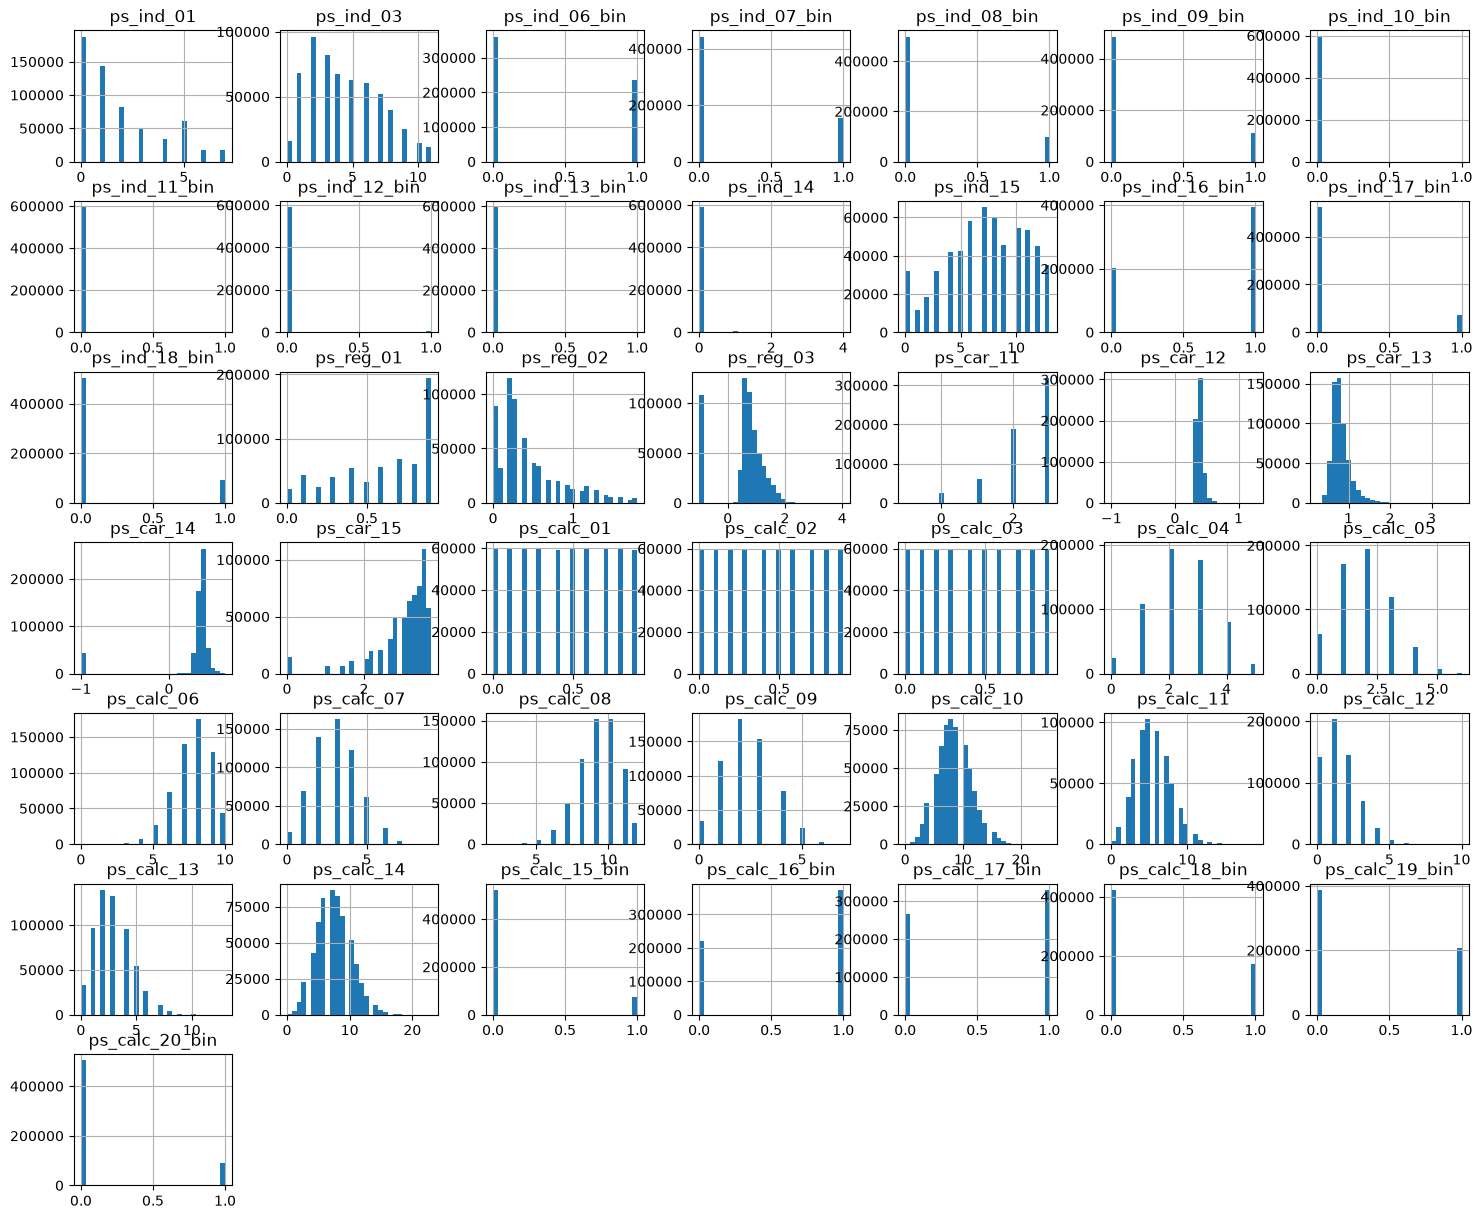

In [12]:
df[num_cols].hist(figsize=(18, 15), bins=30)
plt.show()

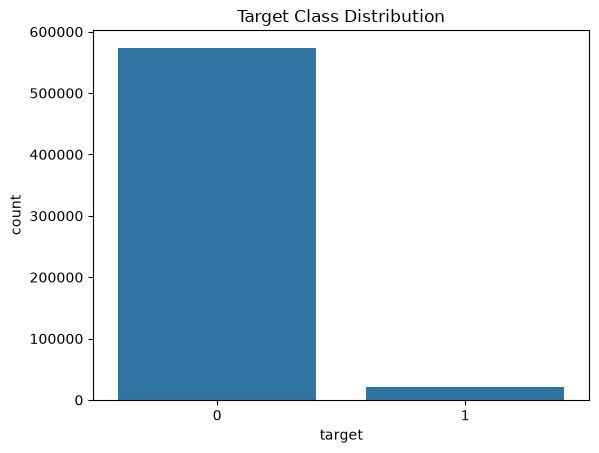

In [13]:
sns.countplot(data=df, x='target')
plt.title('Target Class Distribution')
plt.show()

In [14]:
for col in cat_cols:
    result = (
        df.groupby(col)['target']
        .agg(['count', 'mean'])
        .rename(columns={'mean': 'claim_rate'})
    )

    result['claim_rate'] *= 100

    print(f"\n{col}")
    print(result)


ps_ind_02_cat
                count  claim_rate
ps_ind_02_cat                    
-1                216   18.518519
 1             431859    3.572462
 2             123573    3.813940
 3              28186    3.721706
 4              11378    4.078045

ps_ind_04_cat
                count  claim_rate
ps_ind_04_cat                    
-1                 83   39.759036
 0             346965    3.479025
 1             248164    3.864380

ps_ind_05_cat
                count  claim_rate
ps_ind_05_cat                    
-1               5809    8.331899
 0             528009    3.386495
 1               8322    4.782504
 2               4184    7.552581
 3               8233    4.299769
 4              18344    5.206062
 5               1649    4.851425
 6              20662    5.933598

ps_car_01_cat
                count  claim_rate
ps_car_01_cat                    
-1                107   31.775701
 0               5904    4.386856
 1               1367    4.681785
 2               2144 

In [15]:
print(df['target'].value_counts())
print(df['target'].value_counts(normalize= True)*100)

target
0    573518
1     21694
Name: count, dtype: int64
target
0    96.355248
1     3.644752
Name: proportion, dtype: float64


In [16]:
for col in cat_cols:
    print(col, df[col].nunique())
    print(df[col].value_counts())

ps_ind_02_cat 5
ps_ind_02_cat
 1    431859
 2    123573
 3     28186
 4     11378
-1       216
Name: count, dtype: int64
ps_ind_04_cat 3
ps_ind_04_cat
 0    346965
 1    248164
-1        83
Name: count, dtype: int64
ps_ind_05_cat 8
ps_ind_05_cat
 0    528009
 6     20662
 4     18344
 1      8322
 3      8233
-1      5809
 2      4184
 5      1649
Name: count, dtype: int64
ps_car_01_cat 13
ps_car_01_cat
 11    207573
 7     179247
 6      62393
 10     50087
 4      26174
 9      20323
 5      18142
 8      15093
 3       6658
 0       5904
 2       2144
 1       1367
-1        107
Name: count, dtype: int64
ps_car_02_cat 3
ps_car_02_cat
 1    493990
 0    101217
-1         5
Name: count, dtype: int64
ps_car_03_cat 3
ps_car_03_cat
-1    411231
 1    110709
 0     73272
Name: count, dtype: int64
ps_car_04_cat 10
ps_car_04_cat
0    496581
1     32115
2     23770
8     20598
9     19034
6      1560
3       640
5       545
4       230
7       139
Name: count, dtype: int64
ps_car_05_cat 3
ps

## 3. Data Preprocessing

Data preprocessing was performed to prepare the dataset for classical machine learning algorithms and neural network architectures.

### 3.1 Missing Value Handling

The dataset uses `-1` to represent missing or unknown values in several features.

Different strategies were applied according to feature type:

- **Numerical features:** Missing values were replaced using the median.
- **Categorical features:** Missing values were represented as a separate category.
- **Missing indicators:** Additional binary features were created to preserve information about missing values.

### 3.2 Feature Grouping

Features were organized into three groups:

- Categorical features
- Numerical features
- Binary features

This separation allowed different preprocessing strategies to be applied according to feature type.

### 3.3 Train, Validation, and Test Sets

The dataset was divided into training, validation, and test sets.

- Training set: Used for model fitting.
- Validation set: Used for model selection and hyperparameter optimization.
- Test set: Reserved for final evaluation.

Preprocessing transformations were fitted using training data only and subsequently applied to the validation and test sets to prevent data leakage.

In [17]:
for col in cat_cols:
    if (df[col]== -1).any():
        df[col + 'missing']=(df[col]== -1).astype(int)

In [18]:
for col in cat_cols:
    df[col]= df[col].replace(-1,df[col].max()+1)

In [19]:
for col in num_cols:
    median= df[col].replace(-1,np.nan).median()
    df[col]= df[col].replace(-1,median)

In [20]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
ps_ind_01,595212.0,1.900378,1.983789,0.000000,0.000000,1.000000,3.000000,7.000000
ps_ind_03,595212.0,4.423318,2.699902,0.000000,2.000000,4.000000,6.000000,11.000000
ps_ind_06_bin,595212.0,0.393742,0.488579,0.000000,0.000000,0.000000,1.000000,1.000000
ps_ind_07_bin,595212.0,0.257033,0.436998,0.000000,0.000000,0.000000,1.000000,1.000000
ps_ind_08_bin,595212.0,0.163921,0.370205,0.000000,0.000000,0.000000,0.000000,1.000000
ps_ind_09_bin,595212.0,0.185304,0.388544,0.000000,0.000000,0.000000,0.000000,1.000000
ps_ind_10_bin,595212.0,0.000373,0.019309,0.000000,0.000000,0.000000,0.000000,1.000000
ps_ind_11_bin,595212.0,0.001692,0.041097,0.000000,0.000000,0.000000,0.000000,1.000000
ps_ind_12_bin,595212.0,0.009439,0.096693,0.000000,0.000000,0.000000,0.000000,1.000000
ps_ind_13_bin,595212.0,0.000948,0.030768,0.000000,0.000000,0.000000,0.000000,1.000000


In [21]:
df['ps_car_13_log'] = np.log1p(df['ps_car_13'])
df['ps_reg_03_log'] = np.log1p(df['ps_reg_03'])

In [22]:
x=df.drop(columns=['target','id'])
y=df['target']
print(x.shape)
print(y.shape)

(595212, 68)
(595212,)


In [23]:
X_train, X_t, y_train, y_t = train_test_split(
    x, y, test_size=0.05, random_state=42, stratify=y
)

# Step 2: Split Temporary subset into Validation (2.5%) and Test (2.5%)
X_val, X_test, y_val, y_test = train_test_split(
    X_t, y_t, test_size=0.5, random_state=42, stratify=y_t  # <-- Fixed: stratify=y_t
)

In [24]:
cat_cols = [c for c in x.columns if '_cat' in c]

bin_cols = [c for c in x.columns if '_bin' in c]

num_cols = [
    c for c in x.columns
    if c not in cat_cols + bin_cols
]

print("Categorical:", len(cat_cols))
print("Binary:", len(bin_cols))
print("Numerical:", len(num_cols))

Categorical: 23
Binary: 17
Numerical: 28


In [25]:
num_proc= Pipeline(
    [
       ('scaler', StandardScaler())
    ]
)

In [26]:
cat_proc =Pipeline(
    [
        ('one_hot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [27]:
prepros = ColumnTransformer(
    [
        ('num',num_proc,num_cols),
        ('cat',cat_proc,cat_cols),
        ('bin','passthrough',bin_cols)
    ]
)

In [28]:
X_train_process= prepros.fit_transform(X_train)

In [29]:
X_val_process=prepros.transform(X_val)
X_test_process=prepros.transform(X_test)


In [30]:
print(X_train_process.shape)
print(X_val_process.shape)

(565451, 247)
(14880, 247)


## 4. Evaluation Metrics

Due to the highly imbalanced nature of the dataset, accuracy is not an appropriate primary evaluation metric.

The following metrics were used to evaluate model performance.

### 4.1 ROC-AUC

The Area Under the Receiver Operating Characteristic Curve measures how effectively a model distinguishes between positive and negative classes across different classification thresholds.

A higher ROC-AUC indicates better ranking performance.

### 4.2 Normalized Gini Coefficient

The original Kaggle competition uses the normalized Gini coefficient as its evaluation metric.

For binary classification, the relationship between ROC-AUC and normalized Gini is:

\[
Gini = 2 \times ROC\text{-}AUC - 1
\]

A higher Gini score indicates better ranking performance.

### 4.3 PR-AUC (Average Precision)

Precision-Recall AUC evaluates the trade-off between precision and recall.

It is particularly useful for imbalanced classification problems because it focuses on the model's ability to identify positive examples.

### Primary Evaluation Strategy

- **Normalized Gini:** Competition-aligned metric.
- **ROC-AUC:** Ranking discrimination metric.
- **PR-AUC:** Positive-class detection performance.

## 5. Classical Machine Learning Models

Classical machine learning algorithms were implemented to establish baseline performance before exploring deep learning architectures.

### 5.1 Logistic Regression

Logistic Regression was selected as the first baseline model.

Class weighting was used to account for the imbalance between positive and negative classes.

### 5.2 Random Forest

Random Forest was implemented as a tree-based ensemble learning approach.

The model combines multiple decision trees to capture nonlinear relationships and interactions between features.

Its performance was compared against Logistic Regression to evaluate whether a nonlinear ensemble approach provided an improvement.

In [31]:
model = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
    random_state=42
)

In [32]:
model.fit(X_train_process,y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [33]:
y_pred_proba=model.predict_proba(X_val_process)[:,1]
print("ROC-AUC:",
      roc_auc_score(y_val,y_pred_proba))

print("PR-AUC:",
      average_precision_score(y_val, y_pred_proba))

ROC-AUC: 0.6367853802683654
PR-AUC: 0.06883681772737614


In [34]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=20,
    min_samples_leaf=10,
    max_features='sqrt',
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_process, y_train)

rf_probs = rf_model.predict_proba(X_val_process)[:, 1]

print("ROC-AUC:", roc_auc_score(y_val, rf_probs))
print("PR-AUC:", average_precision_score(y_val, rf_probs))

ROC-AUC: 0.6206277643750073
PR-AUC: 0.06260136678505651


## 6. Deep Learning Experiments

After establishing classical machine learning baselines, neural network architectures were implemented using PyTorch.

The experiments focused on comparing different representations of categorical features.

### 6.1 One-Hot Encoding MLP

A Multi-Layer Perceptron (MLP) was implemented using one-hot encoded categorical features.

The architecture consisted of:

- Input layer.
- Two hidden layers.
- Batch Normalization.
- ReLU activation.
- Dropout regularization.
- Output layer producing a prediction logit.

`BCEWithLogitsLoss` was used as the loss function, with `pos_weight` to address class imbalance.

The Adam optimizer was used to update model parameters.

### 6.2 Hyperparameter Optimization with Optuna

Optuna was used to search for suitable hyperparameters for the One-Hot MLP.

The search included:

- Hidden layer dimensions.
- Dropout rates.
- Learning rate.
- Weight decay.
- Batch size.
- Optimizer selection.

The objective was to maximize validation PR-AUC.

The best hyperparameter configuration was then used to train the final One-Hot MLP.

### 6.3 Categorical Embeddings MLP

A second MLP architecture was developed using embedding layers to represent categorical features.

Instead of expanding categorical variables into multiple one-hot encoded columns, each categorical feature was mapped to a trainable dense vector.

The architecture combined:

- Learned categorical embeddings.
- Standardized numerical features.
- Binary features.
- Fully connected hidden layers.
- Batch Normalization.
- ReLU activation.
- Dropout regularization.

This experiment explored whether learned dense representations of categorical variables could improve predictive performance compared with one-hot encoding.

In [35]:
X_train_arr = X_train_process.toarray() if hasattr(X_train_process, 'toarray') else X_train_process
X_val_arr=X_val_process.toarray() if hasattr(X_val_process,"toarray") else X_val_process
X_test_arr=X_test_process.toarray() if hasattr(X_test_process,"toarray") else X_test_process

In [36]:
#converting datatype to tensor for MLP
X_train_np = np.asarray(X_train_arr, dtype=np.float32)
X_val_np   = np.asarray(X_val_arr,   dtype=np.float32)
X_test_np  = np.asarray(X_test_arr,  dtype=np.float32)

In [37]:
y_train_np = np.asarray(y_train, dtype=np.float32).reshape(-1, 1)
y_val_np = np.asarray(y_val, dtype=np.float32).reshape(-1, 1)
y_test_np= np.asarray(y_test, dtype=np.float32).reshape(-1,1)

In [38]:
X_train_tensor = torch.tensor(X_train_np)
y_train_tensor = torch.tensor(y_train_np)

X_val_tensor = torch.tensor(X_val_np)
y_val_tensor = torch.tensor(y_val_np)

X_test_tensor = torch.tensor(X_test_np)
y_test_tensor = torch.tensor(y_test_np)

In [39]:
train_dataset=TensorDataset(
    X_train_tensor,
    y_train_tensor
)
val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)
test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

In [40]:
batch_size = 512
train_loader = DataLoader(dataset = train_dataset,batch_size=batch_size,shuffle = True)
val_loader = DataLoader(dataset = val_dataset,batch_size=batch_size,shuffle = False)
test_loader = DataLoader(dataset = test_dataset,batch_size=batch_size,shuffle = False)

In [41]:
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 1105
Validation batches: 30
Test batches: 30


In [42]:
class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.network(x)

In [43]:
device = torch.device( "cuda" if torch.cuda.is_available else "cpu")

In [44]:
input_dim = X_train_tensor.shape[1]
model =MLP(input_dim).to(device)
print(f"device is {device}")
print(model)

device is cuda
MLP(
  (network): Sequential(
    (0): Linear(in_features=247, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [45]:
positive_count = y_train_np.sum()
negative_count = len(y_train_np) - positive_count

In [46]:
pos_weight = torch.tensor(
    [negative_count/positive_count],
    dtype = torch.float32
).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight = pos_weight)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

In [47]:
print("Positive weight:", pos_weight.item())

Positive weight: 26.437089920043945


In [48]:
print(type(X_train_process))
print(X_train_process.shape)

<class 'scipy.sparse._csr.csr_matrix'>
(565451, 247)


In [49]:
print("Train:", X_train_tensor.shape)
print("Validation:", X_val_tensor.shape)
print("Test:", X_test_tensor.shape)

print("Train memory (MB):",
      X_train_tensor.nelement() * X_train_tensor.element_size() / 1024**2)

Train: torch.Size([565451, 247])
Validation: torch.Size([14880, 247])
Test: torch.Size([14881, 247])
Train memory (MB): 532.7850227355957


In [50]:
X_batch, y_batch = next(iter(train_loader))

print("Features:", X_batch.shape)
print("Targets:", y_batch.shape)
print("Feature dtype:", X_batch.dtype)

Features: torch.Size([512, 247])
Targets: torch.Size([512, 1])
Feature dtype: torch.float32


In [51]:
EPOCHS = 30
PATIENCE = 5

In [52]:

def train_one_epoch(model, loader,  criterion,optimizer, device):

    model.train()
    total_loss = 0.0

    for X_batch, y_batch in tqdm(
        loader, desc="Training", leave=False
    ):

        X_batch = X_batch.to(device, non_blocking=True)
        y_batch = y_batch.to(device, non_blocking=True)

        optimizer.zero_grad()

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X_batch.shape[0]

    return total_loss / len(loader.dataset)


In [53]:
def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    total_loss = 0.0
    all_probs = []
    all_targets = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device, non_blocking=True)
            y_batch = y_batch.to(device, non_blocking=True)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            probs = torch.sigmoid(logits)

            total_loss += loss.item() * X_batch.size(0)

            all_probs.append(probs.cpu().numpy())
            all_targets.append(y_batch.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    all_probs = np.concatenate(all_probs).ravel()
    all_targets = np.concatenate(all_targets).ravel()

    roc_auc = roc_auc_score(all_targets, all_probs)
    pr_auc = average_precision_score(all_targets, all_probs)

    return avg_loss, roc_auc, pr_auc

In [54]:
best_pr_auc = 0.0
best_epoch = 0
patience_counter = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "val_roc_auc": [],
    "val_pr_auc": []
}

best_model_state = None

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_roc, val_pr = validate_one_epoch(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_roc_auc"].append(val_roc)
    history["val_pr_auc"].append(val_pr)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"ROC-AUC: {val_roc:.4f} | "
        f"PR-AUC: {val_pr:.4f}"
    )

    if val_pr > best_pr_auc:

        best_pr_auc = val_pr
        best_epoch = epoch + 1
        patience_counter = 0

        best_model_state = copy.deepcopy(model.state_dict())

        torch.save(
            best_model_state,
            "best_mlp_model.pth"
        )

    else:

        patience_counter += 1

    if patience_counter >= PATIENCE:

        print(f"\nEarly stopping at epoch {epoch+1}")
        break

print("\nBest epoch:", best_epoch)
print("Best validation PR-AUC:", best_pr_auc)

Training:   0%|          | 0/1105 [00:00<?, ?it/s]

Epoch [1/30] Train Loss: 1.2966 | Val Loss: 1.2816 | ROC-AUC: 0.6331 | PR-AUC: 0.0692


Training:   0%|          | 0/1105 [00:00<?, ?it/s]

Epoch [2/30] Train Loss: 1.2796 | Val Loss: 1.2806 | ROC-AUC: 0.6360 | PR-AUC: 0.0684


Training:   0%|          | 0/1105 [00:00<?, ?it/s]

Epoch [3/30] Train Loss: 1.2749 | Val Loss: 1.2767 | ROC-AUC: 0.6384 | PR-AUC: 0.0689


... (2 outputs left out)

Training:   0%|          | 0/1105 [00:00<?, ?it/s]

Epoch [5/30] Train Loss: 1.2669 | Val Loss: 1.2811 | ROC-AUC: 0.6340 | PR-AUC: 0.0667


Training:   0%|          | 0/1105 [00:00<?, ?it/s]

Epoch [6/30] Train Loss: 1.2627 | Val Loss: 1.2856 | ROC-AUC: 0.6298 | PR-AUC: 0.0664

Early stopping at epoch 6

Best epoch: 1
Best validation PR-AUC: 0.06920385094499941


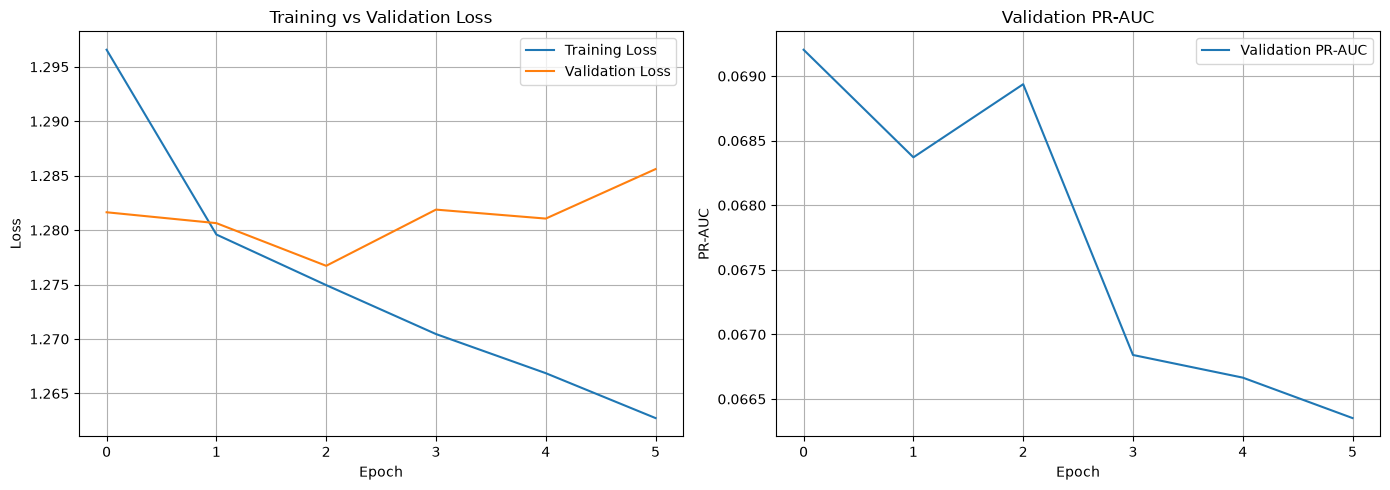

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(history["train_loss"], label="Training Loss")
axes[0].plot(history["val_loss"], label="Validation Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# PR-AUC curve
axes[1].plot(history["val_pr_auc"], label="Validation PR-AUC")
axes[1].set_title("Validation PR-AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("PR-AUC")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [56]:
model.load_state_dict(
    torch.load("best_mlp_model.pth", map_location=device)
)

model.eval()

print("Restored best model from epoch:", best_epoch)
print("Best validation PR-AUC:", best_pr_auc)

Restored best model from epoch: 1
Best validation PR-AUC: 0.06920385094499941


In [57]:
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_dataset = TensorDataset(
    X_train_tensor.cpu(),
    y_train_tensor.cpu()
)

val_dataset = TensorDataset(
    X_val_tensor.cpu(),
    y_val_tensor.cpu()
)

input_dim = X_train_tensor.shape[1]

# Calculate class weight using training data only
positive_count = y_train_tensor.sum()
negative_count = len(y_train_tensor) - positive_count

pos_weight = (negative_count / positive_count).to(device)

print("Input dimensions:", input_dim)
print("Device:", device)
print("Positive weight:", pos_weight.item())

Input dimensions: 247
Device: cuda
Positive weight: 26.437089920043945


In [58]:
class MLP(nn.Module):

    def __init__(self, input_dim, hidden1, hidden2, dropout1, dropout2):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, hidden1),
            nn.BatchNorm1d(hidden1),
            nn.ReLU(),
            nn.Dropout(dropout1),

            nn.Linear(hidden1, hidden2),
            nn.BatchNorm1d(hidden2),
            nn.ReLU(),
            nn.Dropout(dropout2),

            nn.Linear(hidden2, 1)
        )

    def forward(self, x):
        return self.network(x)

In [59]:
def objective(trial):

    # Reproducibility
    torch.manual_seed(SEED)
    np.random.seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    # -----------------------------
    # 1. Hyperparameter search
    # -----------------------------

    hidden1 = trial.suggest_categorical(
        "hidden1", [128, 256, 384]
    )

    hidden2 = trial.suggest_categorical(
        "hidden2", [64, 128, 192]
    )

    # Ensure second layer is smaller than first
    if hidden2 >= hidden1:
        raise optuna.TrialPruned()

    dropout1 = trial.suggest_float(
        "dropout1", 0.1, 0.5
    )

    dropout2 = trial.suggest_float(
        "dropout2", 0.1, 0.4
    )

    learning_rate = trial.suggest_float(
        "learning_rate", 1e-4, 3e-3, log=True
    )

    weight_decay = trial.suggest_float(
        "weight_decay", 1e-7, 1e-3, log=True
    )

    batch_size = trial.suggest_categorical(
        "batch_size", [512, 1024, 2048]
    )

    optimizer_name = trial.suggest_categorical(
        "optimizer", ["Adam", "AdamW"]
    )

    # -----------------------------
    # 2. DataLoaders
    # -----------------------------

    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=1024,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    # -----------------------------
    # 3. Initialize model
    # -----------------------------

    model = MLP(
        input_dim=input_dim,
        hidden1=hidden1,
        hidden2=hidden2,
        dropout1=dropout1,
        dropout2=dropout2
    ).to(device)

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=pos_weight
    )

    if optimizer_name == "Adam":
        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=learning_rate,
            weight_decay=weight_decay
        )
    else:
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=learning_rate,
            weight_decay=weight_decay
        )

    # -----------------------------
    # 4. Training configuration
    # -----------------------------

    EPOCHS = 30
    PATIENCE = 5

    best_pr_auc = 0.0
    patience_counter = 0

    # -----------------------------
    # 5. Training and validation
    # -----------------------------

    for epoch in range(EPOCHS):

        # Training
        model.train()
        total_train_loss = 0.0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(
                device, non_blocking=True
            )

            y_batch = y_batch.to(
                device, non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            logits = model(X_batch)

            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

            total_train_loss += (
                loss.item() * X_batch.size(0)
            )

        train_loss = (
            total_train_loss / len(train_loader.dataset)
        )

        # Validation
        model.eval()

        total_val_loss = 0.0
        all_probs = []
        all_targets = []

        with torch.no_grad():

            for X_batch, y_batch in val_loader:

                X_batch = X_batch.to(
                    device, non_blocking=True
                )

                y_batch = y_batch.to(
                    device, non_blocking=True
                )

                logits = model(X_batch)

                loss = criterion(logits, y_batch)

                probs = torch.sigmoid(logits)

                total_val_loss += (
                    loss.item() * X_batch.size(0)
                )

                all_probs.append(
                    probs.cpu().numpy()
                )

                all_targets.append(
                    y_batch.cpu().numpy()
                )

        val_loss = (
            total_val_loss / len(val_loader.dataset)
        )

        all_probs = np.concatenate(all_probs).ravel()
        all_targets = np.concatenate(all_targets).ravel()

        val_pr_auc = average_precision_score(
            all_targets, all_probs
        )

        # -----------------------------
        # 6. Optuna pruning
        # -----------------------------

        trial.report(val_pr_auc, epoch)

        if trial.should_prune():
            raise optuna.TrialPruned()

        # -----------------------------
        # 7. Early stopping
        # -----------------------------

        if val_pr_auc > best_pr_auc:

            best_pr_auc = val_pr_auc
            patience_counter = 0

        else:

            patience_counter += 1

        if patience_counter >= PATIENCE:
            break

    return best_pr_auc

In [60]:
study = optuna.create_study(
    direction = "maximize",

    sampler = optuna.samplers.TPESampler(
        seed = 42
    ),

    pruner = optuna.pruners.MedianPruner(
        n_startup_trials = 5,
        n_warmup_steps = 5
    )
)

[I 2026-11-08 13:59:32,067] A new study created in memory with name: no-name-cb909c90-2239-4552-bc82-6f546e3504eb


In [96]:
study.optimize(objective, n_trials=30, show_progress_bar = True)

  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-07 15:22:28,207] Trial 0 finished with value: 0.07064882972982854 and parameters: {'hidden1': 256, 'hidden2': 64, 'dropout1': 0.12323344486727979, 'dropout2': 0.3598528437324806, 'learning_rate': 0.0007725378389307352, 'weight_decay': 6.796578090758147e-05, 'batch_size': 1024, 'optimizer': 'Adam'}. Best is trial 0 with value: 0.07064882972982854.
[I 2026-11-07 15:25:34,654] Trial 1 finished with value: 0.0676977558430437 and parameters: {'hidden1': 384, 'hidden2': 192, 'dropout1': 0.15579754426081674, 'dropout2': 0.18764339456056545, 'learning_rate': 0.0003476649150592621, 'weight_decay': 6.6723671704642e-06, 'batch_size': 512, 'optimizer': 'Adam'}. Best is trial 0 with value: 0.07064882972982854.
[I 2026-11-07 15:25:34,661] Trial 2 pruned. 
[I 2026-11-07 15:27:35,381] Trial 3 finished with value: 0.06852316983017684 and parameters: {'hidden1': 384, 'hidden2': 192, 'dropout1': 0.11375540844608736, 'dropout2': 0.37279612062363465, 'learning_rate': 0.00024112898115291975, 'wei

In [97]:
print("Best Trial:", study.best_trial.number)

print("\nBest Validation PR-AUC:")
print(study.best_value)

print("\nBest Hyperparameters:")

for param, value in study.best_params.items():
    print(f"{param}: {value}")

Best Trial: 22

Best Validation PR-AUC:
0.07286458840655255

Best Hyperparameters:
hidden1: 256
hidden2: 128
dropout1: 0.22463422885191925
dropout2: 0.1951202931658358
learning_rate: 0.00020032836753650145
weight_decay: 1.2463565473193302e-07
batch_size: 1024
optimizer: Adam


In [98]:
results = study.trials_dataframe()

results = results.sort_values(
    by="value",
    ascending=False
)

display(results.head(10))

,number,value,datetime_start,datetime_complete,duration,params_batch_size,params_dropout1,params_dropout2,params_hidden1,params_hidden2,params_learning_rate,params_optimizer,params_weight_decay,system_attrs_tpe:relative_params:0,state
22,22,0.072865,2026-11-07 16:12:18.897845,2026-11-07 16:15:28.866782,0 days 00:03:09.968937,1024.0,0.224634,0.195120,256,128,0.000200,Adam,1.246357e-07,"{""hidden1"": 256, ""hidden2"": 128}",COMPLETE
26,26,0.072860,2026-11-07 16:23:24.936754,2026-11-07 16:25:38.017489,0 days 00:02:13.080735,1024.0,0.240911,0.310743,256,128,0.000135,Adam,2.815374e-07,"{""hidden1"": 256, ""hidden2"": 128}",COMPLETE
17,17,0.072703,2026-11-07 16:02:00.757879,2026-11-07 16:03:57.182076,0 days 00:01:56.424197,1024.0,0.204532,0.143140,256,128,0.000206,Adam,1.227518e-07,"{""hidden1"": 256, ""hidden2"": 128}",COMPLETE
25,25,0.072678,2026-11-07 16:21:00.093951,2026-11-07 16:23:24.933144,0 days 00:02:24.839193,1024.0,0.232967,0.265296,256,128,0.000146,Adam,7.328373e-07,"{""hidden1"": 256, ""hidden2"": 128}",COMPLETE
27,27,0.072539,2026-11-07 16:25:38.023130,2026-11-07 16:28:02.097221,0 days 00:02:24.074091,2048.0,0.317805,0.300172,256,128,0.000112,Adam,2.376526e-07,"{""hidden1"": 256, ""hidden2"": 128}",COMPLETE
24,24,0.072529,2026-11-07 16:17:57.530258,2026-11-07 16:21:00.089675,0 days 00:03:02.559417,1024.0,0.170345,0.277672,256,128,0.000153,Adam,8.584737e-07,"{""hidden1"": 256, ""hidden2"": 128}",COMPLETE
21,21,0.072214,2026-11-07 16:08:41.838214,2026-11-07 16:12:18.891835,0 days 00:03:37.053621,1024.0,0.177937,0.141150,256,128,0.000208,Adam,2.098370e-06,"{""hidden1"": 256, ""hidden2"": 128}",COMPLETE
11,11,0.072199,2026-11-07 15:40:24.371153,2026-11-07 15:42:50.999205,0 days 00:02:26.628052,1024.0,0.251842,0.105932,256,128,0.002495,Adam,5.875684e-04,"{""hidden1"": 256, ""hidden2"": 128}",COMPLETE
4,4,0.072169,2026-11-07 15:27:35.386705,2026-11-07 15:29:40.577151,0 days 00:02:05.190446,1024.0,0.178393,0.113568,256,128,0.000302,AdamW,3.586816e-06,NaN,COMPLETE
23,23,0.072034,2026-11-07 16:15:28.870437,2026-11-07 16:17:57.526474,0 days 00:02:28.656037,1024.0,0.205722,0.202891,256,128,0.000189,Adam,1.684381e-07,"{""hidden1"": 256, ""hidden2"": 128}",COMPLETE


In [101]:
plot_optimization_history(study).show()

plot_param_importances(study).show()

plot_parallel_coordinate(study).show()

ImportError: Tried to import 'plotly' but failed. Please make sure that the package is installed correctly to use this feature. Actual error: No module named 'plotly'.

In [109]:
# Reproducibility
SEED = [42, 123, 2026]

torch.manual_seed(SEED[1])
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED[1])

# Best hyperparameters from Optuna
best_params = study.best_params

# DataLoaders
generator = torch.Generator().manual_seed(SEED[1])

train_loader = DataLoader(
    train_dataset,
    batch_size=best_params["batch_size"],
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1024,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# Fresh model
best_model = MLP(
    input_dim=input_dim,
    hidden1=best_params["hidden1"],
    hidden2=best_params["hidden2"],
    dropout1=best_params["dropout1"],
    dropout2=best_params["dropout2"]
).to(device)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.Adam(
    best_model.parameters(),
    lr=best_params["learning_rate"],
    weight_decay=best_params["weight_decay"]
)

# Training configuration
EPOCHS = 30
PATIENCE = 5

best_pr_auc = 0.0
patience_counter = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "val_pr_auc": [],
    "val_roc_auc": []
}

In [110]:
for epoch in range(EPOCHS):

    # Training
    best_model.train()
    total_train_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device, non_blocking=True)
        y_batch = y_batch.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = best_model(X_batch)
        loss = criterion(logits, y_batch)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    train_loss = total_train_loss / len(train_loader.dataset)

    # Validation
    best_model.eval()

    total_val_loss = 0.0
    all_probs = []
    all_targets = []

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device, non_blocking=True)
            y_batch = y_batch.to(device, non_blocking=True)

            logits = best_model(X_batch)
            loss = criterion(logits, y_batch)

            probs = torch.sigmoid(logits)

            total_val_loss += loss.item() * X_batch.size(0)

            all_probs.append(probs.cpu().numpy())
            all_targets.append(y_batch.cpu().numpy())

    val_loss = total_val_loss / len(val_loader.dataset)

    all_probs = np.concatenate(all_probs).ravel()
    all_targets = np.concatenate(all_targets).ravel()

    val_pr_auc = average_precision_score(all_targets, all_probs)
    val_roc_auc = roc_auc_score(all_targets, all_probs)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_pr_auc"].append(val_pr_auc)
    history["val_roc_auc"].append(val_roc_auc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"ROC-AUC: {val_roc_auc:.4f} | "
        f"PR-AUC: {val_pr_auc:.5f}"
    )

    # Save best model
    if val_pr_auc > best_pr_auc:

        best_pr_auc = val_pr_auc
        patience_counter = 0

        torch.save(
            best_model.state_dict(),
            "best_optuna_mlp.pth"
        )

        best_epoch = epoch + 1

    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break

print("\nBest epoch:", best_epoch)
print("Best validation PR-AUC:", best_pr_auc)

Epoch [1/30] Train Loss: 1.3065 | Val Loss: 1.2844 | ROC-AUC: 0.6280 | PR-AUC: 0.06376
Epoch [2/30] Train Loss: 1.2850 | Val Loss: 1.2777 | ROC-AUC: 0.6358 | PR-AUC: 0.06995
Epoch [3/30] Train Loss: 1.2756 | Val Loss: 1.2748 | ROC-AUC: 0.6399 | PR-AUC: 0.06918
Epoch [4/30] Train Loss: 1.2711 | Val Loss: 1.2774 | ROC-AUC: 0.6384 | PR-AUC: 0.06796
Epoch [5/30] Train Loss: 1.2659 | Val Loss: 1.2728 | ROC-AUC: 0.6425 | PR-AUC: 0.06993
Epoch [6/30] Train Loss: 1.2619 | Val Loss: 1.2754 | ROC-AUC: 0.6405 | PR-AUC: 0.06796
Epoch [7/30] Train Loss: 1.2574 | Val Loss: 1.2800 | ROC-AUC: 0.6370 | PR-AUC: 0.06814
Early stopping triggered.

Best epoch: 2
Best validation PR-AUC: 0.06994822647103831


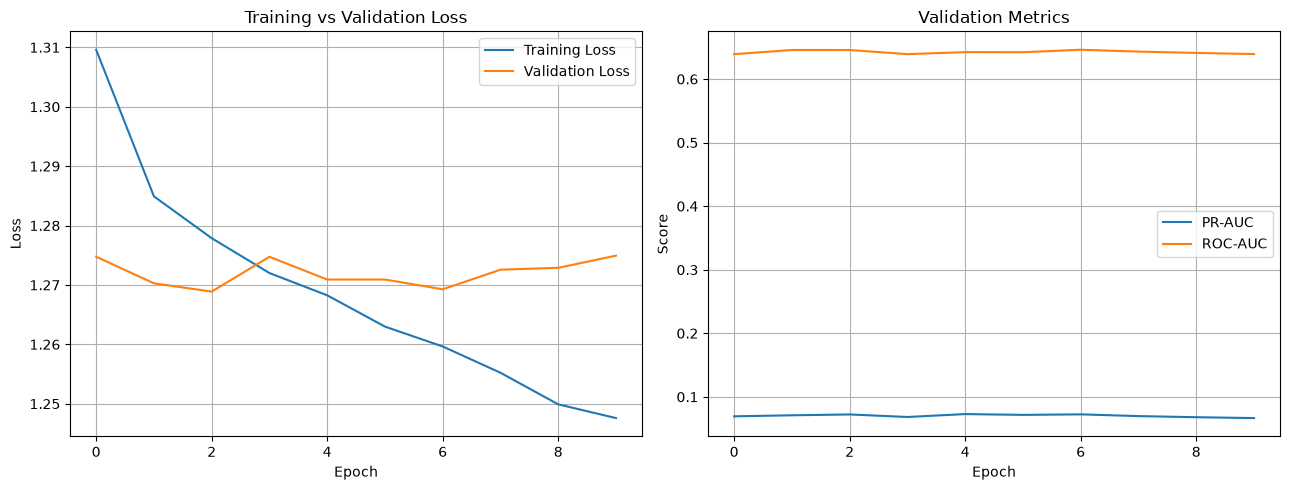

In [104]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history["train_loss"], label="Training Loss")
axes[0].plot(history["val_loss"], label="Validation Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid()

axes[1].plot(history["val_pr_auc"], label="PR-AUC")
axes[1].plot(history["val_roc_auc"], label="ROC-AUC")
axes[1].set_title("Validation Metrics")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

In [61]:
# Identify missing-indicator columns
missing_cols = [col for col in cat_cols if col.endswith("_catmissing")]

# Move them from numerical to binary
cat_cols = [col for col in cat_cols if col not in missing_cols]
bin_cols = bin_cols + missing_cols

print("Numerical features:", len(num_cols))
print("Binary features:", len(bin_cols))
print("Missing indicators moved:", len(missing_cols))
print(cat_cols)

Numerical features: 28
Binary features: 26
Missing indicators moved: 9
['ps_ind_02_cat', 'ps_ind_04_cat', 'ps_ind_05_cat', 'ps_car_01_cat', 'ps_car_02_cat', 'ps_car_03_cat', 'ps_car_04_cat', 'ps_car_05_cat', 'ps_car_06_cat', 'ps_car_07_cat', 'ps_car_08_cat', 'ps_car_09_cat', 'ps_car_10_cat', 'ps_car_11_cat']


In [62]:

print(len(cat_cols))


14


In [63]:
for col in cat_cols:
    print(
        f"{col}: "
        f"{X_train[col].nunique()} unique categories"
    )

ps_ind_02_cat: 5 unique categories
ps_ind_04_cat: 3 unique categories
ps_ind_05_cat: 8 unique categories
ps_car_01_cat: 13 unique categories
ps_car_02_cat: 3 unique categories
ps_car_03_cat: 3 unique categories
ps_car_04_cat: 10 unique categories
ps_car_05_cat: 3 unique categories
ps_car_06_cat: 18 unique categories
ps_car_07_cat: 3 unique categories
ps_car_08_cat: 2 unique categories
ps_car_09_cat: 6 unique categories
ps_car_10_cat: 3 unique categories
ps_car_11_cat: 104 unique categories


In [64]:
categorical_maps = {}
cardinalities = {} 


X_train_cat = pd.DataFrame(index=X_train.index)
X_val_cat = pd.DataFrame(index=X_val.index)
X_test_cat = pd.DataFrame(index=X_test.index)


for col in cat_cols: 

    categories = pd.Index(pd.unique(X_train[col]))


    category_map = {
        category: idx
        for idx, category in enumerate(categories)
    }
    

    categorical_maps[col] = category_map
    cardinalities[col] = len(categories)
    
    
    unknown_id = len(categories) 

    X_train_cat[col] = (
        X_train[col]
        .map(category_map)
        .fillna(unknown_id)
        .astype(np.int64)
    )

    X_val_cat[col] = (
        X_val[col]
        .map(category_map)
        .fillna(unknown_id)
        .astype(np.int64)
    )

    X_test_cat[col] = (
        X_test[col]
        .map(category_map)
        .fillna(unknown_id)
        .astype(np.int64)
    )

In [65]:
scaler = StandardScaler()

X_train_num = scaler.fit_transform(
    X_train[num_cols]
)

X_val_num = scaler.transform(
    X_val[num_cols]
)

X_test_num = scaler.transform(
    X_test[num_cols]
)

print("Numerical processing completed!")

Numerical processing completed!


In [66]:
X_train_bin = X_train[bin_cols].to_numpy(
    dtype=np.float32
)

X_val_bin = X_val[bin_cols].to_numpy(
    dtype=np.float32
)

X_test_bin = X_test[bin_cols].to_numpy(
    dtype=np.float32
)

print("Binary processing completed!")

Binary processing completed!


In [67]:
# Categorical tensors
X_train_cat_tensor = torch.tensor(
    X_train_cat.to_numpy(), dtype=torch.long
)

X_val_cat_tensor = torch.tensor(
    X_val_cat.to_numpy(), dtype=torch.long
)

X_test_cat_tensor = torch.tensor(
    X_test_cat.to_numpy(), dtype=torch.long
)


# Numerical tensors
X_train_num_tensor = torch.tensor(
    X_train_num, dtype=torch.float32
)

X_val_num_tensor = torch.tensor(
    X_val_num, dtype=torch.float32
)

X_test_num_tensor = torch.tensor(
    X_test_num, dtype=torch.float32
)


# Binary tensors
X_train_bin_tensor = torch.tensor(
    X_train_bin, dtype=torch.float32
)

X_val_bin_tensor = torch.tensor(
    X_val_bin, dtype=torch.float32
)

X_test_bin_tensor = torch.tensor(
    X_test_bin, dtype=torch.float32
)


# Target tensors
y_train_tensor = torch.tensor(
    np.asarray(y_train), dtype=torch.float32
).reshape(-1, 1)

y_val_tensor = torch.tensor(
    np.asarray(y_val), dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    np.asarray(y_test), dtype=torch.float32
).reshape(-1, 1)

In [68]:
print("TRAIN SHAPES")

print("Categorical:", X_train_cat_tensor.shape)
print("Numerical:", X_train_num_tensor.shape)
print("Binary:", X_train_bin_tensor.shape)
print("Target:", y_train_tensor.shape)

print("\nVALIDATION SHAPES")

print("Categorical:", X_val_cat_tensor.shape)
print("Numerical:", X_val_num_tensor.shape)
print("Binary:", X_val_bin_tensor.shape)
print("Target:", y_val_tensor.shape)

print("\nTEST SHAPES")

print("Categorical:", X_test_cat_tensor.shape)
print("Numerical:", X_test_num_tensor.shape)
print("Binary:", X_test_bin_tensor.shape)
print("Target:", y_test_tensor.shape)

TRAIN SHAPES
Categorical: torch.Size([565451, 14])
Numerical: torch.Size([565451, 28])
Binary: torch.Size([565451, 26])
Target: torch.Size([565451, 1])

VALIDATION SHAPES
Categorical: torch.Size([14880, 14])
Numerical: torch.Size([14880, 28])
Binary: torch.Size([14880, 26])
Target: torch.Size([14880, 1])

TEST SHAPES
Categorical: torch.Size([14881, 14])
Numerical: torch.Size([14881, 28])
Binary: torch.Size([14881, 26])
Target: torch.Size([14881, 1])


In [69]:
train_dataset = TensorDataset(
    X_train_cat_tensor,
    X_train_num_tensor,
    X_train_bin_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_cat_tensor,
    X_val_num_tensor,
    X_val_bin_tensor,
    y_val_tensor
)

test_dataset = TensorDataset(
    X_test_cat_tensor,
    X_test_num_tensor,
    X_test_bin_tensor,
    y_test_tensor
)

In [70]:
BATCH_SIZE = 1024

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

In [71]:
cat_batch, num_batch, bin_batch, y_batch = next(
    iter(train_loader)
)

print("Categorical batch:", cat_batch.shape)
print("Numerical batch:", num_batch.shape)
print("Binary batch:", bin_batch.shape)
print("Target batch:", y_batch.shape)

Categorical batch: torch.Size([1024, 14])
Numerical batch: torch.Size([1024, 28])
Binary batch: torch.Size([1024, 26])
Target batch: torch.Size([1024, 1])


In [72]:
device = ("cuda" if torch.cuda.is_available() else "cpu")
positive_count = y_train_tensor.sum()
negative_count = len(y_train_tensor) - positive_count

pos_weight = (
    negative_count / positive_count
).to(device)

print("Positive weight:", pos_weight.item())

Positive weight: 26.437089920043945


In [73]:
cardinality_list = [cardinalities[col] for col in cat_cols]

embedding_dims = [
    min(16, max(2, int(np.ceil(np.sqrt(cardinality)))))
    for cardinality in cardinality_list
]

for col, cardinality, dim in zip(cat_cols, cardinality_list, embedding_dims):
    print(f"{col}: {cardinality} categories -> {dim}-dim embedding")

print("Total embedding dimensions:", sum(embedding_dims))

ps_ind_02_cat: 5 categories -> 3-dim embedding
ps_ind_04_cat: 3 categories -> 2-dim embedding
ps_ind_05_cat: 8 categories -> 3-dim embedding
ps_car_01_cat: 13 categories -> 4-dim embedding
ps_car_02_cat: 3 categories -> 2-dim embedding
ps_car_03_cat: 3 categories -> 2-dim embedding
ps_car_04_cat: 10 categories -> 4-dim embedding
ps_car_05_cat: 3 categories -> 2-dim embedding
ps_car_06_cat: 18 categories -> 5-dim embedding
ps_car_07_cat: 3 categories -> 2-dim embedding
ps_car_08_cat: 2 categories -> 2-dim embedding
ps_car_09_cat: 6 categories -> 3-dim embedding
ps_car_10_cat: 3 categories -> 2-dim embedding
ps_car_11_cat: 104 categories -> 11-dim embedding
Total embedding dimensions: 47


In [74]:
class EmbeddingMLP(nn.Module):

    def __init__(
        self,
        cardinalities,
        embedding_dims,
        num_numeric,
        num_binary,
        hidden1=256,
        hidden2=128,
        dropout1=0.225,
        dropout2=0.195
    ):
        super().__init__()

        
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, embedding_dim)
            for cardinality, embedding_dim
            in zip(cardinalities, embedding_dims)
        ])

        
        total_embedding_dim = sum(embedding_dims)

        input_dim = (
            total_embedding_dim
            + num_numeric
            + num_binary
        )

        
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden1),
            nn.BatchNorm1d(hidden1),
            nn.ReLU(),
            nn.Dropout(dropout1),

            nn.Linear(hidden1, hidden2),
            nn.BatchNorm1d(hidden2),
            nn.ReLU(),
            nn.Dropout(dropout2),

            nn.Linear(hidden2, 1)
        )

    def forward(self, x_cat, x_num, x_bin):

        
        embedded_features = [
            embedding(x_cat[:, i])
            for i, embedding in enumerate(self.embeddings)
        ]

        
        x_cat_emb = torch.cat(embedded_features, dim=1)

        # Combine all feature groups
        x = torch.cat(
            [x_cat_emb, x_num, x_bin],
            dim=1
        )

        # Generate prediction logit
        return self.network(x)

In [75]:
model = EmbeddingMLP(
    cardinalities=cardinality_list,
    embedding_dims=embedding_dims,
    num_numeric=X_train_num_tensor.shape[1],
    num_binary=X_train_bin_tensor.shape[1],
    hidden1=256,
    hidden2=128,
    dropout1=0.225,
    dropout2=0.195
).to(device)

print(model)

print("\nTotal parameters:",
      sum(p.numel() for p in model.parameters()))

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

EmbeddingMLP(
  (embeddings): ModuleList(
    (0): Embedding(5, 3)
    (1): Embedding(3, 2)
    (2): Embedding(8, 3)
    (3): Embedding(13, 4)
    (4-5): 2 x Embedding(3, 2)
    (6): Embedding(10, 4)
    (7): Embedding(3, 2)
    (8): Embedding(18, 5)
    (9): Embedding(3, 2)
    (10): Embedding(2, 2)
    (11): Embedding(6, 3)
    (12): Embedding(3, 2)
    (13): Embedding(104, 11)
  )
  (network): Sequential(
    (0): Linear(in_features=101, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.225, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.195, inplace=False)
    (8): Linear(in_features=128, out_features=1, bias=True)
  )
)

Total parameters: 61328
Trainable parameters: 61328


In [76]:
criterion = nn.BCEWithLogitsLoss(
    pos_weight = pos_weight
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0002,
    weight_decay=1.25e-7
)

In [77]:
model.eval()

with torch.no_grad():

    x_cat, x_num, x_bin, y = next(iter(train_loader))

    x_cat = x_cat.to(device)
    x_num = x_num.to(device)
    x_bin = x_bin.to(device)

    output = model(x_cat, x_num, x_bin)

    print("Categorical batch:", x_cat.shape)
    print("Numerical batch:", x_num.shape)
    print("Binary batch:", x_bin.shape)
    print("Model output:", output.shape)
    print("Target:", y.shape)

Categorical batch: torch.Size([1024, 14])
Numerical batch: torch.Size([1024, 28])
Binary batch: torch.Size([1024, 26])
Model output: torch.Size([1024, 1])
Target: torch.Size([1024, 1])


In [78]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=30,
    patience=5
):

    best_pr_auc = 0.0
    best_epoch = 0
    best_weights = copy.deepcopy(model.state_dict())
    patience_counter = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "roc_auc": [],
        "pr_auc": []
    }

    for epoch in range(epochs):

        # --------------------
        # Training
        # --------------------
        model.train()
        train_loss = 0.0

        for x_cat, x_num, x_bin, y in train_loader:

            x_cat = x_cat.to(device)
            x_num = x_num.to(device)
            x_bin = x_bin.to(device)
            y = y.to(device)

            optimizer.zero_grad()

            logits = model(x_cat, x_num, x_bin)

            loss = criterion(logits, y)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * y.size(0)

        train_loss /= len(train_loader.dataset)

        # --------------------
        # Validation
        # --------------------
        model.eval()

        val_loss = 0.0
        all_predictions = []
        all_targets = []

        with torch.no_grad():

            for x_cat, x_num, x_bin, y in val_loader:

                x_cat = x_cat.to(device)
                x_num = x_num.to(device)
                x_bin = x_bin.to(device)
                y = y.to(device)

                logits = model(x_cat, x_num, x_bin)

                loss = criterion(logits, y)

                val_loss += loss.item() * y.size(0)

                probabilities = torch.sigmoid(logits)

                all_predictions.extend(
                    probabilities.cpu().numpy().ravel()
                )

                all_targets.extend(
                    y.cpu().numpy().ravel()
                )

        val_loss /= len(val_loader.dataset)

        roc_auc = roc_auc_score(
            all_targets, all_predictions
        )

        pr_auc = average_precision_score(
            all_targets, all_predictions
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["roc_auc"].append(roc_auc)
        history["pr_auc"].append(pr_auc)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"ROC-AUC: {roc_auc:.4f} | "
            f"PR-AUC: {pr_auc:.4f}"
        )

        # --------------------
        # Early stopping
        # --------------------
        if pr_auc > best_pr_auc:

            best_pr_auc = pr_auc
            best_epoch = epoch + 1

            best_weights = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:
            patience_counter += 1

        if patience_counter >= patience:

            print("\nEarly stopping triggered.")
            break

    model.load_state_dict(best_weights)

    print(f"\nBest epoch: {best_epoch}")
    print(f"Best validation PR-AUC: {best_pr_auc:.6f}")

    return model, history

In [79]:
model, history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=30,
    patience=5
)

Epoch [1/30] Train Loss: 1.3096 | Val Loss: 1.2929 | ROC-AUC: 0.6157 | PR-AUC: 0.0606
Epoch [2/30] Train Loss: 1.2927 | Val Loss: 1.2849 | ROC-AUC: 0.6286 | PR-AUC: 0.0625
Epoch [3/30] Train Loss: 1.2846 | Val Loss: 1.2845 | ROC-AUC: 0.6293 | PR-AUC: 0.0635
Epoch [4/30] Train Loss: 1.2795 | Val Loss: 1.2810 | ROC-AUC: 0.6334 | PR-AUC: 0.0674
Epoch [5/30] Train Loss: 1.2738 | Val Loss: 1.2781 | ROC-AUC: 0.6373 | PR-AUC: 0.0690
Epoch [6/30] Train Loss: 1.2729 | Val Loss: 1.2772 | ROC-AUC: 0.6383 | PR-AUC: 0.0679
Epoch [7/30] Train Loss: 1.2692 | Val Loss: 1.2773 | ROC-AUC: 0.6385 | PR-AUC: 0.0674
Epoch [8/30] Train Loss: 1.2660 | Val Loss: 1.2754 | ROC-AUC: 0.6406 | PR-AUC: 0.0698
Epoch [9/30] Train Loss: 1.2633 | Val Loss: 1.2739 | ROC-AUC: 0.6424 | PR-AUC: 0.0703
Epoch [10/30] Train Loss: 1.2600 | Val Loss: 1.2753 | ROC-AUC: 0.6418 | PR-AUC: 0.0696
Epoch [11/30] Train Loss: 1.2588 | Val Loss: 1.2738 | ROC-AUC: 0.6434 | PR-AUC: 0.0693
Epoch [12/30] Train Loss: 1.2557 | Val Loss: 1.2752 

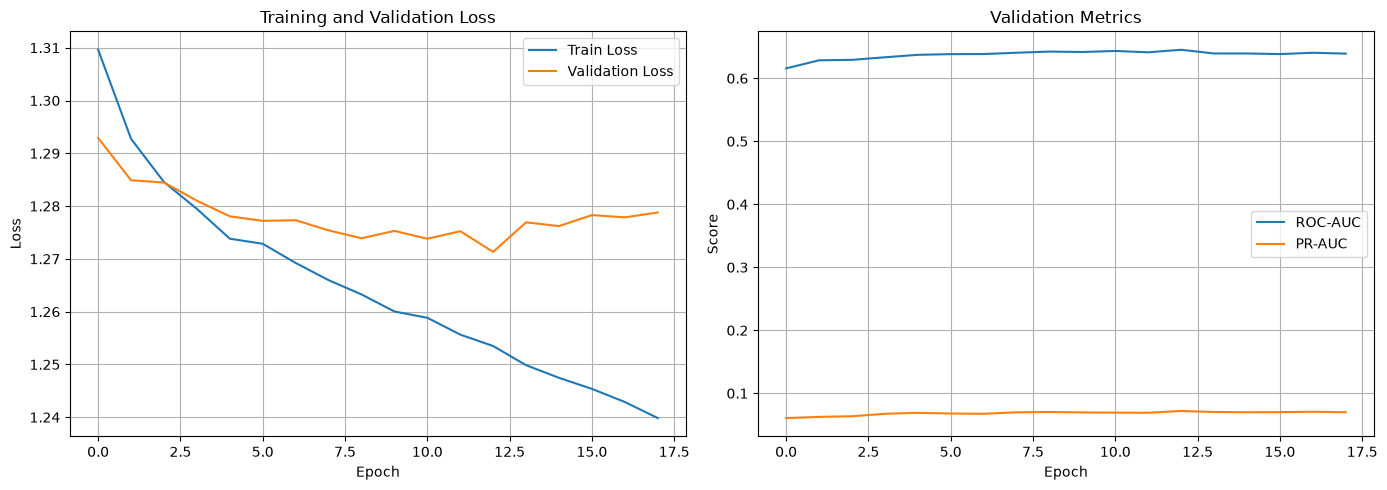

In [80]:


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Validation Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid()

axes[1].plot(history["roc_auc"], label="ROC-AUC")
axes[1].plot(history["pr_auc"], label="PR-AUC")
axes[1].set_title("Validation Metrics")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

## 7. Model Evaluation and Comparison

All models were evaluated using the validation set.

The following table summarizes their best observed validation performance.

| Model | ROC-AUC | Normalized Gini | PR-AUC |
|---|---:|---:|---:|
| Logistic Regression | 0.6342 | 0.2684 | 0.06783 |
| Random Forest | 0.6256 | 0.2513 | 0.06110 |
| One-Hot MLP | **0.6425** | **0.2850** | 0.06995 |
| Embedding MLP | 0.6367 | 0.2734 | **0.07209** |

### Observations

- One-Hot MLP achieved the highest ROC-AUC and normalized Gini among the evaluated models.
- Embedding MLP achieved the highest PR-AUC.
- Logistic Regression provided a competitive classical baseline.
- Random Forest did not outperform Logistic Regression with the selected configuration.
- Categorical embeddings provided a useful alternative feature representation, although they did not produce the highest Gini score.

The best ROC-AUC and PR-AUC values may correspond to different training epochs.

## 8. Conclusion and Key Learnings

This project explored classical machine learning and deep learning approaches for an imbalanced binary classification problem.

Starting with Logistic Regression and Random Forest, the experiments progressed toward neural network architectures using one-hot encoding and learned categorical embeddings.

Optuna was also used to investigate hyperparameter configurations for the One-Hot MLP.

### Key Findings

- One-Hot MLP achieved the highest normalized Gini score of **0.2850**.
- Embedding MLP achieved the highest PR-AUC of **0.07209**.
- Increasing model complexity does not necessarily guarantee better performance.
- Feature representation can influence neural network performance.
- Appropriate evaluation metrics are essential when working with imbalanced datasets.
- Validation performance, random initialization, and reproducibility must be considered when comparing models.

### Final Takeaway

The main objective of this project was to gain practical experience in developing, training, evaluating, and comparing machine learning and deep learning models.

It provided an opportunity to explore the complete experimentation workflow, from data preprocessing and baseline development to neural network optimization and model evaluation.